In [1]:
from pathlib import Path
import platform
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the dataset relative to this notebook
DATA_DIR = Path("../Dataset/riiid-test-answer-prediction")

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("Dataset path:", DATA_DIR.resolve())

# Check files
for filename in [
    "train.csv",
    "questions.csv",
    "lectures.csv",
    "example_test.csv",
    "example_sample_submission.csv"
]:
    file_path = DATA_DIR / filename
    print(f"{filename}: {'Found' if file_path.exists() else 'NOT FOUND'}")

Python version: 3.14.0
PyTorch version: 2.10.0
MPS available: True
Dataset path: /Users/aryangahlot/Desktop/Coding/AI-ML/PersonalizedLearning/Training/Dataset/riiid-test-answer-prediction
train.csv: Found
questions.csv: Found
lectures.csv: Found
example_test.csv: Found
example_sample_submission.csv: Found


In [2]:
train_path = DATA_DIR / "train.csv"
questions_path = DATA_DIR / "questions.csv"
lectures_path = DATA_DIR / "lectures.csv"

# Read only the first 100,000 rows for initial exploration
train_sample = pd.read_csv(train_path, nrows=100_000)

# These metadata files are much smaller
questions = pd.read_csv(questions_path)
lectures = pd.read_csv(lectures_path)

print("Training sample shape:", train_sample.shape)
print("Questions shape:", questions.shape)
print("Lectures shape:", lectures.shape)

Training sample shape: (100000, 10)
Questions shape: (13523, 5)
Lectures shape: (418, 4)


In [3]:
display(train_sample.head())
display(questions.head())
display(lectures.head())

,row_id,timestamp,user_id,content_id,content_type_id,task_container_id,user_answer,answered_correctly,prior_question_elapsed_time,prior_question_had_explanation
0,0,0,115,5692,0,1,3,1,NaN,NaN
1,1,56943,115,5716,0,2,2,1,37000.0,False
2,2,118363,115,128,0,0,0,1,55000.0,False
3,3,131167,115,7860,0,3,0,1,19000.0,False
4,4,137965,115,7922,0,4,1,1,11000.0,False


,question_id,bundle_id,correct_answer,part,tags
0,0,0,0,1,51 131 162 38
1,1,1,1,1,131 36 81
2,2,2,0,1,131 101 162 92
3,3,3,0,1,131 149 162 29
4,4,4,3,1,131 5 162 38


,lecture_id,tag,part,type_of
0,89,159,5,concept
1,100,70,1,concept
2,185,45,6,concept
3,192,79,5,solving question
4,317,156,5,solving question


In [4]:
print("Column data types:")
display(train_sample.dtypes)

print("Missing values:")
display(train_sample.isnull().sum())

print("Answer correctness counts:")
display(train_sample["answered_correctly"].value_counts(dropna=False))

print("Interaction types:")
display(train_sample["content_type_id"].value_counts())

Column data types:


row_id                              int64
timestamp                           int64
user_id                             int64
content_id                          int64
content_type_id                     int64
task_container_id                   int64
user_answer                         int64
answered_correctly                  int64
prior_question_elapsed_time       float64
prior_question_had_explanation     object
dtype: object

Missing values:


row_id                               0
timestamp                            0
user_id                              0
content_id                           0
content_type_id                      0
task_container_id                    0
user_answer                          0
answered_correctly                   0
prior_question_elapsed_time       2166
prior_question_had_explanation     348
dtype: int64

Answer correctness counts:


answered_correctly
 1    67326
 0    30856
-1     1818
Name: count, dtype: int64

Interaction types:


content_type_id
0    98182
1     1818
Name: count, dtype: int64

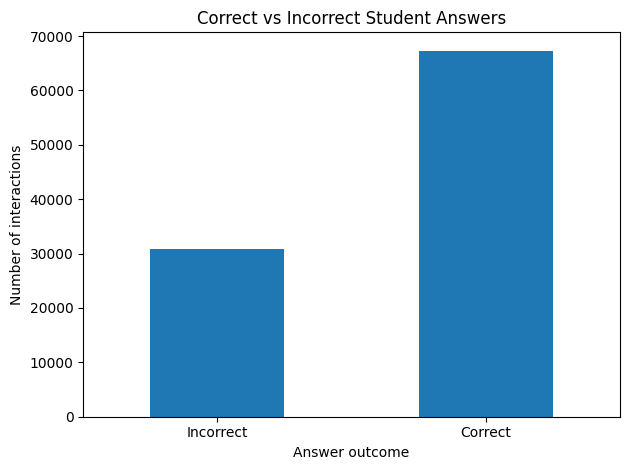

In [5]:
question_rows = train_sample[
    train_sample["content_type_id"] == 0
]

counts = (
    question_rows["answered_correctly"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

counts.index = ["Incorrect", "Correct"]

counts.plot(kind="bar")
plt.title("Correct vs Incorrect Student Answers")
plt.xlabel("Answer outcome")
plt.ylabel("Number of interactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Keep only question interactions.
# Lecture rows have content_type_id = 1 and answered_correctly = -1.
question_data = train_sample[
    (train_sample["content_type_id"] == 0) &
    (train_sample["answered_correctly"].isin([0, 1]))
].copy()

# Sort interactions chronologically within each student
question_data = question_data.sort_values(
    ["user_id", "timestamp", "row_id"]
).reset_index(drop=True)

print("Question interactions:", len(question_data))
print("Unique students:", question_data["user_id"].nunique())

print("\nCorrectness distribution:")
print(question_data["answered_correctly"].value_counts(normalize=True))

print("\nInteractions per student:")
print(question_data.groupby("user_id").size().describe())

Question interactions: 98182
Unique students: 349

Correctness distribution:
answered_correctly
1    0.685727
0    0.314273
Name: proportion, dtype: float64

Interactions per student:
count     349.000000
mean      281.323782
std       802.266402
min         1.000000
25%        30.000000
50%        47.000000
75%       155.000000
max      7476.000000
dtype: float64


In [7]:
question_metadata = questions[
    ["question_id", "part", "tags"]
].copy()

question_data = question_data.merge(
    question_metadata,
    left_on="content_id",
    right_on="question_id",
    how="left",
    validate="many_to_one"
)

print(question_data[
    ["user_id", "content_id", "answered_correctly", "part", "tags"]
].head(10))

print(
    "Interactions without question metadata:",
    question_data["part"].isna().sum()
)

   user_id  content_id  answered_correctly  part            tags
0      115        5692                   1     5             151
1      115        5716                   1     5             168
2      115         128                   1     1      131 149 92
3      115        7860                   1     1      131 104 81
4      115        7922                   1     1      131 149 92
5      115         156                   1     1  131 101 162 38
6      115          51                   1     1      131 187 81
7      115          50                   1     1      131 101 38
8      115        7896                   1     1  131 104 162 81
9      115        7863                   1     1       131 68 92
Interactions without question metadata: 0


In [8]:
# Select a student with at least 5 question interactions
student_counts = question_data.groupby("user_id").size()
eligible_students = student_counts[student_counts >= 5]

student_id = eligible_students.index[0]

student_history = question_data[
    question_data["user_id"] == student_id
].copy()

display(
    student_history[
        ["timestamp", "content_id", "answered_correctly", "part", "tags"]
    ].head(10)
)

,timestamp,content_id,answered_correctly,part,tags
0,0,5692,1,5,151
1,56943,5716,1,5,168
2,118363,128,1,1,131 149 92
3,131167,7860,1,1,131 104 81
4,137965,7922,1,1,131 149 92
5,157063,156,1,1,131 101 162 38
6,176092,51,1,1,131 187 81
7,194190,50,1,1,131 101 38
8,212463,7896,1,1,131 104 162 81
9,230983,7863,1,1,131 68 92


In [9]:
student_history = student_history.sort_values(
    ["timestamp", "row_id"]
).reset_index(drop=True)

display(
    student_history[
        [
            "row_id",
            "timestamp",
            "user_id",
            "content_id",
            "answered_correctly",
            "part",
            "tags",
        ]
    ].head(10)
)

,row_id,timestamp,user_id,content_id,answered_correctly,part,tags
0,0,0,115,5692,1,5,151
1,1,56943,115,5716,1,5,168
2,2,118363,115,128,1,1,131 149 92
3,3,131167,115,7860,1,1,131 104 81
4,4,137965,115,7922,1,1,131 149 92
5,5,157063,115,156,1,1,131 101 162 38
6,6,176092,115,51,1,1,131 187 81
7,7,194190,115,50,1,1,131 101 38
8,8,212463,115,7896,1,1,131 104 162 81
9,9,230983,115,7863,1,1,131 68 92


In [10]:
import numpy as np

MAX_SEQ_LEN = 100

# Map question IDs to embedding indices.
# Index 0 is reserved for padding.
question_ids = sorted(question_data["content_id"].unique())

question_to_idx = {
    question_id: idx + 1
    for idx, question_id in enumerate(question_ids)
}

NUM_QUESTIONS = len(question_to_idx) + 1

print("Number of question IDs:", len(question_ids))
print("Embedding vocabulary size:", NUM_QUESTIONS)

Number of question IDs: 11321
Embedding vocabulary size: 11322


In [11]:

X_history = []
X_target_question = []
y_target = []
sequence_users = []
sequence_lengths = []

for user_id, group in question_data.groupby("user_id", sort=False):
    group = group.sort_values(["timestamp", "row_id"])

    q_ids = group["content_id"].map(question_to_idx).to_numpy()
    answers = group["answered_correctly"].to_numpy()

    for target_idx in range(1, len(group)):
        start_idx = max(0, target_idx - MAX_SEQ_LEN)

        history_q = q_ids[start_idx:target_idx]
        history_a = answers[start_idx:target_idx]
        length = len(history_q)

        padded_q = np.zeros(MAX_SEQ_LEN, dtype=np.int32)
        padded_a = np.zeros(MAX_SEQ_LEN, dtype=np.int32)

        # Right padding
        padded_q[:length] = history_q
        padded_a[:length] = history_a

        X_history.append(np.stack([padded_q, padded_a], axis=-1))
        X_target_question.append(q_ids[target_idx])
        y_target.append(answers[target_idx])
        sequence_users.append(user_id)
        sequence_lengths.append(length)

X_history = np.asarray(X_history, dtype=np.int32)
X_target_question = np.asarray(X_target_question, dtype=np.int32)
y_target = np.asarray(y_target, dtype=np.float32)
sequence_users = np.asarray(sequence_users)
sequence_lengths = np.asarray(sequence_lengths, dtype=np.int64)

print("History tensor:", X_history.shape)
print("Sequence lengths:", sequence_lengths.shape)


History tensor: (97833, 100, 2)
Sequence lengths: (97833,)


In [12]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X_history,
        y_target,
        groups=sequence_users
    )
)

X_hist_train = X_history[train_idx]
X_q_train = X_target_question[train_idx]
y_train = y_target[train_idx]
lengths_train = sequence_lengths[train_idx]

X_hist_val = X_history[val_idx]
X_q_val = X_target_question[val_idx]
y_val = y_target[val_idx]
lengths_val = sequence_lengths[val_idx]

print("Training examples:", len(y_train))
print("Validation examples:", len(y_val))
print("Training lengths:", lengths_train.shape)
print("Validation lengths:", lengths_val.shape)

Training examples: 82576
Validation examples: 15257
Training lengths: (82576,)
Validation lengths: (15257,)


In [13]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Training device:", device)


class StudentSequenceDataset(Dataset):
    def __init__(self, histories, target_questions, labels, lengths):
        self.histories = torch.as_tensor(histories, dtype=torch.long)
        self.target_questions = torch.as_tensor(target_questions, dtype=torch.long)
        self.labels = torch.as_tensor(labels, dtype=torch.float32)
        self.lengths = torch.as_tensor(lengths, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            self.histories[index],
            self.target_questions[index],
            self.labels[index],
            self.lengths[index],
        )


train_dataset = StudentSequenceDataset(
    X_hist_train, X_q_train, y_train, lengths_train
)

val_dataset = StudentSequenceDataset(
    X_hist_val, X_q_val, y_val, lengths_val
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training device: mps
Train batches: 646
Validation batches: 60


## LSTM

In [14]:
from torch.nn.utils.rnn import pack_padded_sequence

class LSTMKnowledgeTracer(nn.Module):
    def __init__(
        self,
        num_questions,
        embedding_dim=64,
        hidden_dim=64
    ):
        super().__init__()

        self.question_embedding = nn.Embedding(
            num_questions, embedding_dim, padding_idx=0
        )

        self.response_embedding = nn.Embedding(
            3, embedding_dim, padding_idx=2
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim * 2,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output = nn.Sequential(
            nn.Linear(hidden_dim + embedding_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, history, target_question, lengths):
        question_ids = history[:, :, 0]
        responses = history[:, :, 1]

        q_emb = self.question_embedding(question_ids)

        response_ids = responses.clone()
        response_ids[question_ids == 0] = 2

        r_emb = self.response_embedding(response_ids)

        x = torch.cat([q_emb, r_emb], dim=-1)

        packed_x = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed_x)

        history_representation = hidden[-1]
        target_emb = self.question_embedding(target_question)

        combined = torch.cat(
            [history_representation, target_emb], dim=-1
        )

        return self.output(combined).squeeze(-1)


model = LSTMKnowledgeTracer(
    num_questions=NUM_QUESTIONS
).to(device)

print(model)

LSTMKnowledgeTracer(
  (question_embedding): Embedding(11322, 64, padding_idx=0)
  (response_embedding): Embedding(3, 64, padding_idx=2)
  (lstm): LSTM(128, 64, batch_first=True)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [15]:
import copy
from sklearn.metrics import roc_auc_score

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

EPOCHS = 5
best_auc = -1
best_state = None

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for histories, target_questions, labels, lengths in train_loader:
        histories = histories.to(device)
        target_questions = target_questions.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(histories, target_questions, lengths)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    train_loss = total_loss / len(train_dataset)

    model.eval()
    val_probs = []
    val_labels = []

    with torch.no_grad():
        for histories, target_questions, labels, lengths in val_loader:
            histories = histories.to(device)
            target_questions = target_questions.to(device)

            logits = model(histories, target_questions, lengths)
            probs = torch.sigmoid(logits)

            val_probs.extend(probs.cpu().numpy())
            val_labels.extend(labels.numpy())

    val_auc = roc_auc_score(val_labels, val_probs)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation ROC-AUC: {val_auc:.4f}"
    )

    if val_auc > best_auc:
        best_auc = val_auc
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)

print("Best validation ROC-AUC:", round(best_auc, 4))

Epoch 1/5 | Train loss: 0.5992 | Validation ROC-AUC: 0.6728
Epoch 2/5 | Train loss: 0.5786 | Validation ROC-AUC: 0.6901
Epoch 3/5 | Train loss: 0.5528 | Validation ROC-AUC: 0.7010
Epoch 4/5 | Train loss: 0.5238 | Validation ROC-AUC: 0.7007
Epoch 5/5 | Train loss: 0.4944 | Validation ROC-AUC: 0.6896
Best validation ROC-AUC: 0.701


## Sakt Model

In [16]:

import torch
import torch.nn as nn

class SAKTKnowledgeTracer(nn.Module):
    def __init__(
        self,
        num_questions,
        max_seq_len=100,
        embedding_dim=64,
        num_heads=4,
        dropout=0.2
    ):
        super().__init__()

        self.question_embedding = nn.Embedding(
            num_questions, embedding_dim, padding_idx=0
        )

        # 0 = incorrect, 1 = correct, 2 = padding
        self.response_embedding = nn.Embedding(
            3, embedding_dim, padding_idx=2
        )

        self.position_embedding = nn.Embedding(
            max_seq_len, embedding_dim
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm = nn.LayerNorm(embedding_dim)

        self.output = nn.Sequential(
            nn.Linear(embedding_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, history, target_question, lengths):
        # history shape: (batch, sequence_length, 2)
        question_ids = history[:, :, 0]
        responses = history[:, :, 1]

        # Represent each previous question and its answer
        q_emb = self.question_embedding(question_ids)

        response_ids = responses.clone()
        response_ids[question_ids == 0] = 2
        r_emb = self.response_embedding(response_ids)

        batch_size, seq_len = question_ids.shape

        positions = torch.arange(
            seq_len, device=history.device
        ).unsqueeze(0).expand(batch_size, -1)

        pos_emb = self.position_embedding(positions)

        interactions = q_emb + r_emb + pos_emb

        # The target question queries relevant past interactions
        query = self.question_embedding(target_question).unsqueeze(1)

        # True means the position is padding and must be ignored
        padding_mask = question_ids == 0

        attended, _ = self.attention(
            query=query,
            key=interactions,
            value=interactions,
            key_padding_mask=padding_mask,
            need_weights=False
        )

        attended = self.norm(attended.squeeze(1))
        target_emb = query.squeeze(1)

        combined = torch.cat([attended, target_emb], dim=-1)

        return self.output(combined).squeeze(-1)


sakt_model = SAKTKnowledgeTracer(
    num_questions=NUM_QUESTIONS,
    max_seq_len=MAX_SEQ_LEN
).to(device)

print(sakt_model)
print("Training device:", device)


SAKTKnowledgeTracer(
  (question_embedding): Embedding(11322, 64, padding_idx=0)
  (response_embedding): Embedding(3, 64, padding_idx=2)
  (position_embedding): Embedding(100, 64)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (output): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Training device: mps


In [17]:

import copy
from sklearn.metrics import roc_auc_score

criterion_sakt = nn.BCEWithLogitsLoss()

optimizer_sakt = torch.optim.Adam(
    sakt_model.parameters(),
    lr=0.001
)

EPOCHS_SAKT = 5
best_sakt_auc = -1
best_sakt_state = None

for epoch in range(EPOCHS_SAKT):
    sakt_model.train()
    total_loss = 0.0

    for histories, target_questions, labels, lengths in train_loader:
        histories = histories.to(device)
        target_questions = target_questions.to(device)
        labels = labels.to(device)

        optimizer_sakt.zero_grad()

        logits = sakt_model(
            histories, target_questions, lengths
        )

        loss = criterion_sakt(logits, labels)
        loss.backward()
        optimizer_sakt.step()

        total_loss += loss.item() * len(labels)

    train_loss = total_loss / len(train_dataset)

    sakt_model.eval()
    val_probs = []
    val_labels = []

    with torch.no_grad():
        for histories, target_questions, labels, lengths in val_loader:
            histories = histories.to(device)
            target_questions = target_questions.to(device)

            logits = sakt_model(
                histories, target_questions, lengths
            )

            probs = torch.sigmoid(logits)
            val_probs.extend(probs.cpu().numpy())
            val_labels.extend(labels.numpy())

    val_auc = roc_auc_score(val_labels, val_probs)

    print(
        f"Epoch {epoch + 1}/{EPOCHS_SAKT} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation ROC-AUC: {val_auc:.4f}"
    )

    if val_auc > best_sakt_auc:
        best_sakt_auc = val_auc
        best_sakt_state = copy.deepcopy(
            sakt_model.state_dict()
        )

sakt_model.load_state_dict(best_sakt_state)

print(
    "Best SAKT validation ROC-AUC:",
    round(best_sakt_auc, 4)
)


Epoch 1/5 | Train loss: 0.6042 | Validation ROC-AUC: 0.6568
Epoch 2/5 | Train loss: 0.5894 | Validation ROC-AUC: 0.6669
Epoch 3/5 | Train loss: 0.5678 | Validation ROC-AUC: 0.6832
Epoch 4/5 | Train loss: 0.5406 | Validation ROC-AUC: 0.6843
Epoch 5/5 | Train loss: 0.5107 | Validation ROC-AUC: 0.6860
Best SAKT validation ROC-AUC: 0.686


In [18]:
print("Model comparison")
print("----------------")
print(f"LSTM best ROC-AUC: {0.7010:.4f}")
print(f"SAKT best ROC-AUC: {best_sakt_auc:.4f}")
print(f"Difference: {best_sakt_auc - 0.7010:+.4f}")

Model comparison
----------------
LSTM best ROC-AUC: 0.7010
SAKT best ROC-AUC: 0.6860
Difference: -0.0150


## Saint Model

In [21]:

import torch
import torch.nn as nn

class SAINTKnowledgeTracer(nn.Module):
    def __init__(
        self,
        num_questions,
        max_seq_len=100,
        embedding_dim=64,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.max_seq_len = max_seq_len

        # Encoder: question representations
        self.question_embedding = nn.Embedding(
            num_questions, embedding_dim, padding_idx=0
        )

        # Decoder: previous response representations
        # 0 = incorrect, 1 = correct, 2 = padding/start token
        self.response_embedding = nn.Embedding(
            3, embedding_dim, padding_idx=2
        )

        # +1 because the target question is appended to the history
        self.question_position = nn.Embedding(
            max_seq_len + 1, embedding_dim
        )
        self.response_position = nn.Embedding(
            max_seq_len + 1, embedding_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=embedding_dim * 4,
            dropout=dropout,
            batch_first=True
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=embedding_dim * 4,
            dropout=dropout,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers
        )

        self.output = nn.Sequential(
            nn.Linear(embedding_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, history, target_question, lengths):
        batch_size = history.size(0)
        history_len = history.size(1)
        total_len = history_len + 1

        lengths = lengths.to(history.device)
        batch_indices = torch.arange(
            batch_size, device=history.device
        )

        # Build question sequence: history + target question
        question_ids = torch.zeros(
            batch_size, total_len,
            dtype=torch.long, device=history.device
        )

        question_ids[:, :history_len] = history[:, :, 0]
        question_ids[batch_indices, lengths] = target_question

        positions = torch.arange(
            total_len, device=history.device
        ).unsqueeze(0).expand(batch_size, -1)

        question_input = (
            self.question_embedding(question_ids)
            + self.question_position(positions)
        )

        # True marks padding positions that attention must ignore
        question_padding_mask = question_ids == 0

        encoded_questions = self.encoder(
            question_input,
            src_key_padding_mask=question_padding_mask
        )

        # Build response sequence. The target response is unknown,
        # so its input is the special padding/start token (index 2).
        response_ids = torch.full(
            (batch_size, total_len),
            2,
            dtype=torch.long,
            device=history.device
        )

        response_ids[:, :history_len] = history[:, :, 1]
        response_ids[:, :history_len][history[:, :, 0] == 0] = 2

        response_input = (
            self.response_embedding(response_ids)
            + self.response_position(positions)
        )

        # Keep history responses and the target position;
        # mask only positions after the target.
        decoder_padding_mask = positions > lengths.unsqueeze(1)

        # Prevent decoder positions from attending to later positions.
        causal_mask = torch.triu(
            torch.ones(
                total_len, total_len,
                dtype=torch.bool, device=history.device
            ),
            diagonal=1
        )

        decoded = self.decoder(
            tgt=response_input,
            memory=encoded_questions,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=decoder_padding_mask,
            memory_key_padding_mask=question_padding_mask
        )

        # Select the decoder output at the target question position.
        target_representation = decoded[
            batch_indices, lengths
        ]

        return self.output(target_representation).squeeze(-1)


saint_model = SAINTKnowledgeTracer(
    num_questions=NUM_QUESTIONS,
    max_seq_len=MAX_SEQ_LEN
).to(device)

print(saint_model)
print("Training device:", device)


SAINTKnowledgeTracer(
  (question_embedding): Embedding(11322, 64, padding_idx=0)
  (response_embedding): Embedding(3, 64, padding_idx=2)
  (question_position): Embedding(101, 64)
  (response_position): Embedding(101, 64)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-1): 2 x Tra

In [22]:

import copy
from sklearn.metrics import roc_auc_score

criterion_saint = nn.BCEWithLogitsLoss()

optimizer_saint = torch.optim.Adam(
    saint_model.parameters(),
    lr=0.001
)

EPOCHS_SAINT = 5
best_saint_auc = -1
best_saint_state = None

for epoch in range(EPOCHS_SAINT):
    saint_model.train()
    total_loss = 0.0

    for histories, target_questions, labels, lengths in train_loader:
        histories = histories.to(device)
        target_questions = target_questions.to(device)
        labels = labels.to(device)

        optimizer_saint.zero_grad()

        logits = saint_model(
            histories, target_questions, lengths
        )

        loss = criterion_saint(logits, labels)
        loss.backward()
        optimizer_saint.step()

        total_loss += loss.item() * len(labels)

    train_loss = total_loss / len(train_dataset)

    saint_model.eval()
    val_probs = []
    val_labels = []

    with torch.no_grad():
        for histories, target_questions, labels, lengths in val_loader:
            histories = histories.to(device)
            target_questions = target_questions.to(device)

            logits = saint_model(
                histories, target_questions, lengths
            )

            probs = torch.sigmoid(logits)
            val_probs.extend(probs.cpu().numpy())
            val_labels.extend(labels.numpy())

    val_auc = roc_auc_score(val_labels, val_probs)

    print(
        f"Epoch {epoch + 1}/{EPOCHS_SAINT} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation ROC-AUC: {val_auc:.4f}"
    )

    if val_auc > best_saint_auc:
        best_saint_auc = val_auc
        best_saint_state = copy.deepcopy(
            saint_model.state_dict()
        )

saint_model.load_state_dict(best_saint_state)

print(
    "Best SAINT validation ROC-AUC:",
    round(best_saint_auc, 4)
)


Epoch 1/5 | Train loss: 0.6055 | Validation ROC-AUC: 0.6547
Epoch 2/5 | Train loss: 0.5997 | Validation ROC-AUC: 0.6576
Epoch 3/5 | Train loss: 0.5959 | Validation ROC-AUC: 0.6546
Epoch 4/5 | Train loss: 0.5896 | Validation ROC-AUC: 0.6408
Epoch 5/5 | Train loss: 0.5779 | Validation ROC-AUC: 0.6231
Best SAINT validation ROC-AUC: 0.6576


In [23]:
print("Model comparison")
print("----------------")
print(f"LSTM  ROC-AUC: {0.7010:.4f}")
print(f"SAKT  ROC-AUC: {0.6860:.4f}")
print(f"SAINT ROC-AUC: {best_saint_auc:.4f}")

Model comparison
----------------
LSTM  ROC-AUC: 0.7010
SAKT  ROC-AUC: 0.6860
SAINT ROC-AUC: 0.6576


In [26]:

import torch
from pathlib import Path

# Create a folder for saved models
model_dir = Path("../saved_models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the best LSTM checkpoint and its configuration
checkpoint = {
    "model_state_dict": model.state_dict(),
    "num_questions": NUM_QUESTIONS,
    "embedding_dim": 64,
    "hidden_dim": 64,
    "max_seq_len": MAX_SEQ_LEN,
    "question_to_idx": question_to_idx,
    "best_validation_auc": best_auc,
}

model_path = model_dir / "lstm_knowledge_tracer.pt"

torch.save(checkpoint, model_path)

print("Model saved to:", model_path.resolve())
print("Best validation ROC-AUC:", best_auc)


Model saved to: /Users/aryangahlot/Desktop/Coding/AI-ML/PersonalizedLearning/Training/saved_models/lstm_knowledge_tracer.pt
Best validation ROC-AUC: 0.7009949079910199
